# Análisis de Biomasa Residual Agrícola en Argentina

**Objetivo**: Estimar la biomasa residual generada por los principales cultivos extensivos a nivel departamental, integrando dos fuentes oficiales: la Bolsa de Cereales de Córdoba y las Estimaciones Agrícolas del Ministerio de Agricultura, Ganadería y Pesca de la Nación (MAGYP).

**Estructura del pipeline**:
1. Ingesta y diagnóstico de datos crudos.
2. Construcción del Índice de Cosecha (IC) y Factor de Residuo (FR).
3. Limpieza de nulos con justificación metodológica.
4. Taxonomía canónica de cultivos.
5. Normalización geográfica.
6. Resolución de agregados vs componentes.
7. Integración multi-fuente con política de prioridad.
8. Validación de invariantes.
9. Cálculo de biomasa residual con flags de validez.
10. Análisis exploratorio y visualización.

In [43]:
# ============================================================
# Librerías
# ============================================================
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
import geopandas as gpd
import pytest

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# 1. Ingesta de Datos

Se cargan las dos fuentes primarias en su forma cruda, sin transformación. El dataset de la Bolsa de Cereales de Buenos Aires fue descartado por utilizar la zonificación PAS en lugar de la división administrativa departamental.

In [44]:
# df_bolsa_cereales_nacion = pd.read_excel("./../data/raw/datos_bolsa_cereales_nacion.csv")  # DESCARTADO: usa Zona PAS
df_bolsa_cereales_cba = pd.read_csv("./../data/raw/datos_bolsa_granos_cba.csv")
df_estimaciones_agricolas = pd.read_csv("./../data/raw/datos_estimaciones.csv", encoding="utf-8-sig")

# 2. Preparación del Índice de Cosecha (IC)

El **Índice de Cosecha (IC)** se define como la proporción del rendimiento en grano respecto a la biomasa aérea total de la planta. Aunque puede variar por mejoras genéticas y prácticas agronómicas, se asume constante siguiendo los valores de referencia publicados en la literatura agronómica.

El **Factor de Residuo (FR)** se deriva como:

$$FR = \frac{1 - IC}{IC}$$

permitiendo estimar la biomasa residual como $\text{Biomasa Residual} = \text{Producción} \times FR$.

In [45]:
# ============================================================
# Tabla de referencia IC/FR
# NOTA: los nombres canónicos se codifican en formato clean_str
#       (minúsculas, sin acentos, sin ñ).
# ============================================================
data = {
    "Cultivo": [
        "maíz", "soja", "trigo", "girasol", "maní", "garbanzo",
        "sorgo", "cebada", "centeno", "avena", "poroto",
        "ajo", "colza", "papa", "lino", "arroz", "algodón",
    ],
    "IC": [
        0.47, 0.45, 0.35, 0.37, 0.40, 0.26,
        0.35, 0.53, 0.22, 0.35, 0.45,
        0.55, 0.28, 0.74, 0.40, 0.45, 0.30,
    ],
    "Fuente bibliográfica": [
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Raposo (2024)",
        "Haro (2022), Promedio variedad granoleico",
        "Promedio de Apáez-Barrios (2017) y Ramacciotti (2015)",
        "Promedio de híbridos obtenido por Zamer y Chiarelli",
        "Cuda (2014)",
        "Zubiaga et al. (2023)",
        "Promedios obtenidos por Zubiaga et al. (2023)",
        "Ortega (2001)",
        "Rizzalli, Villalobos & Orgaz (2002). European Journal of Agronomy",
        "Unkovich et al. (Advances in Agronomy); Lu et al. (2016)",
        "Xu et al. (análisis QUEFTS, Agronomy Journal); rango 0.70-0.85",
        "Estudios de componentes de rendimiento (ADAS/AHDB)",
        "Hay (1995) y estudios recientes de riego/N (rango 0.40-0.55)",
        "Estudios regionales (Xinjiang y revisiones globales de lint HI)",
    ]
}

df_IC = pd.DataFrame(data)
df_IC["FR"] = (1 - df_IC["IC"]) / df_IC["IC"]
df_IC.head(20)

,Cultivo,IC,Fuente bibliográfica,FR
0,maíz,0.47,Bolsa de Cereales de Buenos Aires (2015),1.127660
1,soja,0.45,Bolsa de Cereales de Buenos Aires (2015),1.222222
2,trigo,0.35,Bolsa de Cereales de Buenos Aires (2015),1.857143
3,girasol,0.37,Raposo (2024),1.702703
4,maní,0.40,"Haro (2022), Promedio variedad granoleico",1.500000
5,garbanzo,0.26,Promedio de Apáez-Barrios (2017) y Ramacciotti...,2.846154
6,sorgo,0.35,Promedio de híbridos obtenido por Zamer y Chia...,1.857143
7,cebada,0.53,Cuda (2014),0.886792
8,centeno,0.22,Zubiaga et al. (2023),3.545455
9,avena,0.35,Promedios obtenidos por Zubiaga et al. (2023),1.857143


### Fuentes bibliográficas de los IC extendidos

| Cultivo   | IC usado | Fuente |
|-----------|----------|--------|
| **ajo**   | 0.55 | Rizzalli, R.H.; Villalobos, F.J.; Orgaz, F. (2002). *Radiation interception, radiation-use efficiency and dry matter partitioning in garlic*. European Journal of Agronomy 18(1-2): 33-43. |
| **colza** | 0.28 | Unkovich et al. (Advances in Agronomy); Lu et al. (2016). Rango típico 0.20-0.28. |
| **papa**  | 0.74 | Xu et al. (análisis QUEFTS en China, n=654). Media 0.74 (rango 0.40-0.95). |
| **lino**  | 0.40 | Valores documentados en ensayos de componentes de rendimiento (ADAS/AHDB). |
| **arroz** | 0.45 | Hay (1995) Annals of Applied Biology + estudios recientes. Rango moderno 0.34-0.55. |
| **algodón** | 0.30 | Lint harvest index típico en regiones áridas (Xinjiang). |

**Nota metodológica**: no se agregaron cultivos sin dato confiable en la literatura (alpiste, jojoba, yerba mate, tung, té, banana, cítricos, caña de azúcar). Estos quedarán marcados como `_valido_biomasa = False` en el cálculo final, con reporte explícito de la exclusión.

# 3. Tratamiento de Datos

## 3.1 Diagnóstico de Valores Nulos

In [46]:
print("================ BOLSA DE CEREALES CBA ================")
print(df_bolsa_cereales_cba.info())
print("\n================ MAGYP ESTIMACIONES ================")
print(df_estimaciones_agricolas.info())

================ BOLSA DE CEREALES CBA ================
<class 'pandas.DataFrame'>
RangeIndex: 4094 entries, 0 to 4093
Data columns (total 10 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   PROVINCIA                        4094 non-null   str    
 1   DEPARTAMENTO                     4094 non-null   str    
 2   CULTIVO                          4094 non-null   str    
 3   CAMPAÑA                          4094 non-null   str    
 4   SEMBRADAS                        4094 non-null   float64
 5   COSECHADAS                       4094 non-null   float64
 6   RENDIMIENTO                      3850 non-null   float64
 7   RENDIMIENTO GRANO LIMPIO Y SECO  215 non-null    float64
 8   PRODUCCIÓN                       3850 non-null   float64
 9   PRODUCCIÓN GRANO LIMPIO Y SECO   215 non-null    float64
dtypes: float64(6), str(4)
memory usage: 448.7 KB
None

================ MAGYP ESTIMACIONES ============

**Diagnóstico**: la Bolsa de Cereales de Córdoba presenta valores nulos únicamente en las columnas `RENDIMIENTO GRANO LIMPIO Y SECO` y `PRODUCCIÓN GRANO LIMPIO Y SECO`, con cobertura marginal (215 de 4094 registros, ~5%). Estas columnas representan una sub-categoría específica (grano en condición comercial) y su exclusión no afecta la variable principal de producción.

El dataset de MAGYP no presenta nulos en la etapa de ingesta, aunque los campos numéricos están codificados como `str` y requieren conversión.

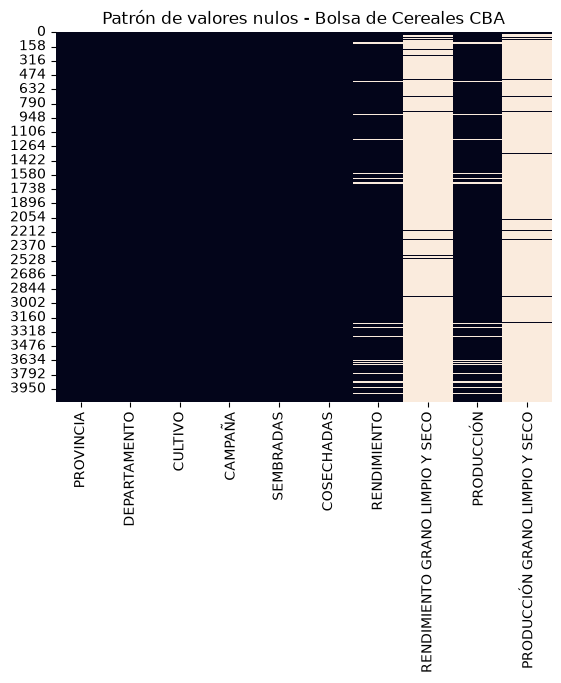

In [47]:
sns.heatmap(df_bolsa_cereales_cba.isnull(), cbar=False)
plt.title("Patrón de valores nulos - Bolsa de Cereales CBA")
plt.show()

## 3.2 Limpieza de la Bolsa de Cereales de Córdoba

Se eliminan las columnas de grano limpio y seco (cobertura 5%, sub-categoría específica) y las filas con nulos residuales. Dado que `Rendimiento = Producción / Superficie`, los nulos en rendimiento coinciden con nulos en producción y no representan información adicional.

In [48]:
df_bolsa_cereales_cba_cleaned = df_bolsa_cereales_cba.drop(
    columns=["RENDIMIENTO GRANO LIMPIO Y SECO", "PRODUCCIÓN GRANO LIMPIO Y SECO"]
).dropna()

print(df_bolsa_cereales_cba_cleaned.info())

<class 'pandas.DataFrame'>
Index: 3850 entries, 0 to 4093
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PROVINCIA     3850 non-null   str    
 1   DEPARTAMENTO  3850 non-null   str    
 2   CULTIVO       3850 non-null   str    
 3   CAMPAÑA       3850 non-null   str    
 4   SEMBRADAS     3850 non-null   float64
 5   COSECHADAS    3850 non-null   float64
 6   RENDIMIENTO   3850 non-null   float64
 7   PRODUCCIÓN    3850 non-null   float64
dtypes: float64(4), str(4)
memory usage: 393.5 KB
None


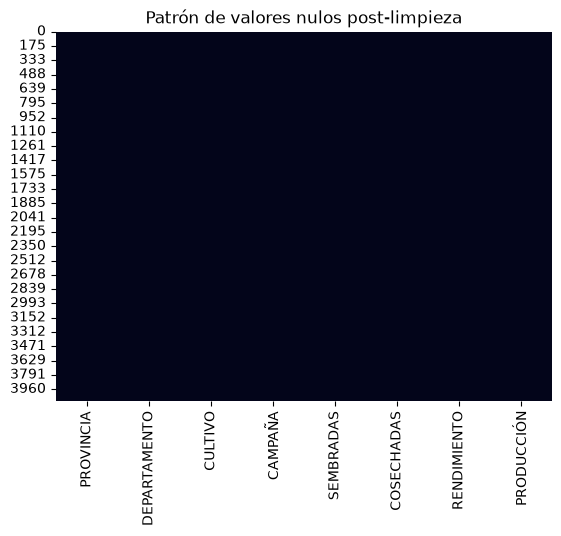

In [49]:
sns.heatmap(df_bolsa_cereales_cba_cleaned.isnull(), cbar=False)
plt.title("Patrón de valores nulos post-limpieza")
plt.show()

# 4. Taxonomía Canónica de Cultivos

La taxonomía define el mapeo determinístico entre nombres raw de cultivos y nombres canónicos, con marca de agregación. **Reglas de negocio embebidas**:

- Los cultivos con nombre canónico compuesto (`caña de azúcar`, `yerba mate`) no se colapsan a la primera palabra.
- Los cultivos biológicamente distintos (`trigo candeal` = *Triticum durum* vs `trigo` = *Triticum aestivum*) se preservan como entidades independientes.
- **Nombres base canónicos** (`soja`, `trigo`, `cebada`, `poroto`, `papa`, `cebolla`) se incluyen como entradas explícitas no-agregadas, ya que aparecen en la fuente CBA sin sufijo `total`.
- Falla bloqueante ante cultivos no mapeados (principio *fail-fast*).

In [50]:
# =================================================================
# CROP_TAXONOMY: fuente de verdad del dominio de cultivos.
# Keys y canonical en formato clean_str (minúsculas, sin acentos, sin ñ).
# =================================================================
CROP_TAXONOMY = {
    # --- Familia soja ---
    "soja":       {"canonical": "soja",   "is_aggregate": False, "components": []},
    "soja 1ra":   {"canonical": "soja",   "is_aggregate": False, "components": []},
    "soja 2da":   {"canonical": "soja",   "is_aggregate": False, "components": []},
    "soja total": {"canonical": "soja",   "is_aggregate": True,
                   "components": ["soja 1ra", "soja 2da"]},

    # --- Familia cebada ---
    "cebada":           {"canonical": "cebada", "is_aggregate": False, "components": []},
    "cebada cervecera": {"canonical": "cebada", "is_aggregate": False, "components": []},
    "cebada forrajera": {"canonical": "cebada", "is_aggregate": False, "components": []},
    "cebada total":     {"canonical": "cebada", "is_aggregate": True,
                         "components": ["cebada cervecera", "cebada forrajera"]},

    # --- Familia poroto ---
    "poroto":        {"canonical": "poroto", "is_aggregate": False, "components": []},
    "poroto alubia": {"canonical": "poroto", "is_aggregate": False, "components": []},
    "poroto negro":  {"canonical": "poroto", "is_aggregate": False, "components": []},
    "poroto otros":  {"canonical": "poroto", "is_aggregate": False, "components": []},
    "poroto total":  {"canonical": "poroto", "is_aggregate": True,
                      "components": ["poroto alubia", "poroto negro", "poroto otros"]},

    # --- Totales sin breakdown y sus nombres base ---
    "trigo":         {"canonical": "trigo",   "is_aggregate": False, "components": []},
    "trigo total":   {"canonical": "trigo",   "is_aggregate": True,  "components": []},
    "papa":          {"canonical": "papa",    "is_aggregate": False, "components": []},
    "papa total":    {"canonical": "papa",    "is_aggregate": True,  "components": []},
    "cebolla":       {"canonical": "cebolla", "is_aggregate": False, "components": []},
    "cebolla total": {"canonical": "cebolla", "is_aggregate": True,  "components": []},

    # --- Cultivos biológicamente/comercialmente distintos: NO merge ---
    "trigo candeal":  {"canonical": "trigo candeal",  "is_aggregate": False, "components": []},
    "cana de azucar": {"canonical": "cana de azucar", "is_aggregate": False, "components": []},
    "yerba mate":     {"canonical": "yerba mate",     "is_aggregate": False, "components": []},

    # --- Cultivos simples (identidad) ---
    "ajo":       {"canonical": "ajo",      "is_aggregate": False, "components": []},
    "algodon":   {"canonical": "algodon",  "is_aggregate": False, "components": []},
    "alpiste":   {"canonical": "alpiste",  "is_aggregate": False, "components": []},
    "arroz":     {"canonical": "arroz",    "is_aggregate": False, "components": []},
    "arveja":    {"canonical": "arveja",   "is_aggregate": False, "components": []},
    "avena":     {"canonical": "avena",    "is_aggregate": False, "components": []},
    "banana":    {"canonical": "banana",   "is_aggregate": False, "components": []},
    "cartamo":   {"canonical": "cartamo",  "is_aggregate": False, "components": []},
    "centeno":   {"canonical": "centeno",  "is_aggregate": False, "components": []},
    "colza":     {"canonical": "colza",    "is_aggregate": False, "components": []},
    "garbanzo":  {"canonical": "garbanzo", "is_aggregate": False, "components": []},
    "girasol":   {"canonical": "girasol",  "is_aggregate": False, "components": []},
    "jojoba":    {"canonical": "jojoba",   "is_aggregate": False, "components": []},
    "lenteja":   {"canonical": "lenteja",  "is_aggregate": False, "components": []},
    "limon":     {"canonical": "limon",    "is_aggregate": False, "components": []},
    "lino":      {"canonical": "lino",     "is_aggregate": False, "components": []},
    "maiz":      {"canonical": "maiz",     "is_aggregate": False, "components": []},
    "mandarina": {"canonical": "mandarina","is_aggregate": False, "components": []},
    "mani":      {"canonical": "mani",     "is_aggregate": False, "components": []},
    "mijo":      {"canonical": "mijo",     "is_aggregate": False, "components": []},
    "naranja":   {"canonical": "naranja",  "is_aggregate": False, "components": []},
    "pomelo":    {"canonical": "pomelo",   "is_aggregate": False, "components": []},
    "sorgo":     {"canonical": "sorgo",    "is_aggregate": False, "components": []},
    "te":        {"canonical": "te",       "is_aggregate": False, "components": []},
    "tung":      {"canonical": "tung",     "is_aggregate": False, "components": []},
}

# 5. Funciones de Normalización

## 5.1 Normalización léxica de strings

Función idempotente que aplica descomposición Unicode NFKD, transliteración ASCII, colapso de espacios múltiples, conversión a minúsculas y strip.

In [51]:
def clean_str(s: str) -> str:
    """
    Normaliza strings para matching determinístico entre fuentes.
    Pipeline: NFKD -> ASCII -> colapsar whitespace -> lowercase -> strip.
    Idempotente: clean_str(clean_str(s)) == clean_str(s).
    """
    if not isinstance(s, str):
        return s
    s = unicodedata.normalize("NFKD", s)
    s = s.encode("ascii", "ignore").decode("ascii")
    s = re.sub(r"\s+", " ", s)
    return s.strip().lower()

## 5.2 Normalización geográfica

Pipeline de normalización canónica de entidades administrativas subprovinciales. Resuelve cuatro mecanismos de variabilidad:

1. **Variabilidad de espaciado**: `chos  malal` → `chos malal`.
2. **Puntuación inconsistente**: `leandro n. alem` → `leandro n alem`.
3. **Abreviación de títulos**: `gral` → `general`, `pte` → `presidente`.
4. **Iniciales vs nombre completo**: `j b alberdi` → `juan b alberdi` (vía alias explícito por provincia).

In [52]:
def strip_periods(s: str) -> str:
    """Reemplaza puntos por espacios y colapsa. Resuelve 'n.' vs 'n'."""
    if not isinstance(s, str):
        return s
    return re.sub(r"\s+", " ", s.replace(".", " ")).strip()


ABBREV_SAFE = {
    "gral":  "general",
    "pte":   "presidente",
    "gob":   "gobernador",
    "dr":    "doctor",
    "dra":   "doctora",
    "cnl":   "coronel",
    "tte":   "teniente",
    "sgt":   "sargento",
    "cap":   "capitan",
}


def expand_abbrevs(s: str, mapping: dict = ABBREV_SAFE) -> str:
    """Expande abreviaturas token a token (no dentro de tokens)."""
    if not isinstance(s, str):
        return s
    return " ".join(mapping.get(tok, tok) for tok in s.split(" "))


# Alias específicos indexados por (provincia_canónica, dept_normalizado).
# Sólo casos residuales no resueltos por reglas genéricas.
DEPT_ALIASES = {
    ("tucuman",             "j b alberdi"):  "juan b alberdi",
    ("santiago del estero", "j f ibarra"):   "juan felipe ibarra",
    ("la pampa",            "quemu quemu"): "quemu quemu",
}


def resolve_dept_alias(provincia: str, dept: str, aliases: dict = DEPT_ALIASES) -> str:
    return aliases.get((provincia, dept), dept)


def normalize_geo(
    df: pd.DataFrame,
    prov_col: str = "Provincia",
    dept_col: str = "Departamento",
    aliases: dict = DEPT_ALIASES,
) -> pd.DataFrame:
    """Normaliza Provincia y Departamento a representación canónica."""
    df = df.copy()
    df[prov_col] = df[prov_col].apply(clean_str)
    df[dept_col] = (
        df[dept_col]
          .apply(clean_str)
          .apply(strip_periods)
          .apply(expand_abbrevs)
    )
    df[dept_col] = [
        resolve_dept_alias(p, d, aliases)
        for p, d in zip(df[prov_col], df[dept_col])
    ]
    return df


def flag_invalid_geo(df: pd.DataFrame, dept_col: str = "Departamento") -> pd.DataFrame:
    """Marca departamentos placeholder o inválidos."""
    df = df.copy()
    df["_dept_valido"] = ~df[dept_col].isin({"sin definir", "", "na", "n/a"})
    return df

# 6. Resolución de Cultivos (total vs componentes)

Función pura que resuelve la coexistencia de registros agregados (`X total`) y componentes (`X variante`) a nivel de clave natural. **Regla**: si existe al menos un agregado en el grupo, se conservan únicamente los agregados.

In [53]:
def resolve_crops(
    df: pd.DataFrame,
    taxonomy: dict,
    raw_col: str = "Cultivo",
    keys: tuple = ("Campaña", "Provincia", "Departamento"),
) -> pd.DataFrame:
    """
    Resuelve coexistencia de agregados y componentes por clave natural.
    Preserva trazabilidad vía columna `_source_cultivo`.
    Falla bloqueante ante cultivos no mapeados.
    """
    df = df.copy()
    unmapped = sorted(set(df[raw_col].unique()) - set(taxonomy.keys()))
    if unmapped:
        raise ValueError(
            f"Cultivos sin mapeo en CROP_TAXONOMY: {unmapped}. "
            "Agregar explícitamente a la taxonomía antes de continuar."
        )
    meta = df[raw_col].map(taxonomy)
    df["_canonical"]    = meta.map(lambda x: x["canonical"])
    df["_is_aggregate"] = meta.map(lambda x: x["is_aggregate"])

    gkey = list(keys) + ["_canonical"]
    df["_has_aggregate"] = (
        df.groupby(gkey, dropna=False)["_is_aggregate"].transform("any")
    )
    keep_mask = (~df["_has_aggregate"]) | (df["_is_aggregate"])
    resolved = df.loc[keep_mask].copy()
    resolved["_source_cultivo"] = resolved[raw_col]
    resolved = resolved.drop(columns=[raw_col, "_is_aggregate", "_has_aggregate"])
    resolved = resolved.rename(columns={"_canonical": "Cultivo"})
    return resolved.reset_index(drop=True)

## 6.1 Tests de invariantes

Cobertura de las reglas de negocio: no duplicación por clave, preservación de componentes sin total, separación de cultivos biológicamente distintos, falla ante entradas no mapeadas.

In [54]:
def test_total_prevalece_sobre_componentes_soja():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 3, "Provincia": ["cordoba"] * 3,
        "Departamento": ["rio cuarto"] * 3,
        "Cultivo": ["soja 1ra", "soja 2da", "soja total"],
        "Producción": [1000, 500, 1500],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 1
    assert out.iloc[0]["Cultivo"] == "soja"
    assert out.iloc[0]["_source_cultivo"] == "soja total"

def test_base_canonico_no_agregado():
    """CBA emite 'soja' sin sufijo total. Debe resolverse como no-agregado."""
    df = pd.DataFrame({
        "Campaña": ["2020/21"], "Provincia": ["cordoba"],
        "Departamento": ["rio cuarto"],
        "Cultivo": ["soja"], "Producción": [1000],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 1
    assert out.iloc[0]["Cultivo"] == "soja"

def test_componentes_se_conservan_sin_total():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 2, "Provincia": ["cordoba"] * 2,
        "Departamento": ["rio cuarto"] * 2,
        "Cultivo": ["soja 1ra", "soja 2da"], "Producción": [1000, 500],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 2
    assert set(out["Cultivo"]) == {"soja"}

def test_trigo_candeal_no_se_consolida_con_trigo():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 2, "Provincia": ["cordoba"] * 2,
        "Departamento": ["rio cuarto"] * 2,
        "Cultivo": ["trigo total", "trigo candeal"],
        "Producción": [10000, 2000],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert set(out["Cultivo"]) == {"trigo", "trigo candeal"}

def test_cultivo_compuesto_no_se_colapsa():
    df = pd.DataFrame({
        "Campaña": ["2020/21"], "Provincia": ["cordoba"],
        "Departamento": ["rio cuarto"],
        "Cultivo": ["cana de azucar"], "Producción": [5000],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert out.iloc[0]["Cultivo"] == "cana de azucar"

def test_fail_fast_ante_cultivo_no_mapeado():
    df = pd.DataFrame({
        "Campaña": ["2020/21"], "Provincia": ["x"],
        "Departamento": ["y"], "Cultivo": ["quinoa"],
        "Producción": [100],
    })
    with pytest.raises(ValueError, match="quinoa"):
        resolve_crops(df, CROP_TAXONOMY)

def test_clean_str_idempotente():
    for s in ["  MAÍZ ", "Cebada  Cervecera", "TRIGO CANDEAL", "Caña de Azúcar"]:
        assert clean_str(clean_str(s)) == clean_str(s)

def test_normalize_geo_colapsa_abreviaturas():
    df = pd.DataFrame({
        "Provincia": ["Córdoba", "Córdoba"],
        "Departamento": ["GRAL. SAN MARTIN", "General San Martín"],
    })
    out = normalize_geo(df)
    assert out["Departamento"].nunique() == 1

## 6.2 Documento de política de consolidación

**POL-CROP-001: Consolidación de registros `X total` vs componentes**

**Alcance**: dataset integrado (CBA + MAGYP) en capa curada.

- **Regla 1 (jerarquía de agregación)**: cuando para una clave `(Campaña, Provincia, Departamento, cultivo_canónico)` coexistan registros agregados y componentes, prevalece el agregado. Los componentes se descartan para esa clave por riesgo de doble conteo.
- **Regla 2 (fallback)**: cuando no exista agregado para una clave, se conservan los componentes y se suman en la etapa de agregación.
- **Regla 3 (cultivos compuestos)**: nombres canónicos de más de una palabra (`caña de azúcar`, `yerba mate`) no se colapsan.
- **Regla 4 (cultivos biológicamente distintos)**: `trigo candeal` (*Triticum durum*) y `trigo` (*Triticum aestivum*) no se consolidan.
- **Regla 5 (fail-fast)**: todo cultivo no presente en la taxonomía genera error bloqueante.

## 6.3 Justificación técnica

El dataset de estimaciones agrícolas de MAGYP presenta, para algunas familias de cultivos, registros concurrentes bajo dos modalidades de reporte: (i) un registro agregado bajo la denominación `<cultivo> total`, y (ii) uno o más registros correspondientes a las variantes que componen dicho agregado. Una suma ingenua sobre la dimensión cultivo produce doble conteo. La resolución se implementa mediante **prioridad jerárquica a nivel de clave natural**, con normalización canónica por tabla declarativa, detección de coexistencia agregado-componente por `groupby.transform("any")`, y falla bloqueante ante entradas no mapeadas. Se preserva trazabilidad mediante `_source_cultivo` para reconstruir el linaje del dato en la capa curada.

# 7. Aplicación a la Bolsa de Cereales de Córdoba

## 7.1 Exploración inicial

In [55]:
print("Cultivos crudos CBA:")
print(sorted(df_bolsa_cereales_cba_cleaned["CULTIVO"].unique()))

Cultivos crudos CBA:
['GARBANZO', 'GIRASOL', 'MAIZ', 'MANI', 'SOJA', 'SORGO', 'SORGO ', 'TRIGO', 'TRIGO CANDEAL']


## 7.2 Pipeline de normalización + resolución

In [56]:
# Renombrar columnas para homogeneizar con el esquema canónico
df_bolsa_cereales_cba_cleaned = df_bolsa_cereales_cba_cleaned.rename(columns={
    "PROVINCIA": "Provincia",
    "DEPARTAMENTO": "Departamento",
    "CULTIVO": "Cultivo",
    "CAMPAÑA": "Campaña",
})

# 1. Normalización léxica del cultivo
df_bolsa_cereales_cba_cleaned["Cultivo"] = (
    df_bolsa_cereales_cba_cleaned["Cultivo"].apply(clean_str)
)

# 2. Normalización geográfica (provincia + departamento)
df_bolsa_cereales_cba_cleaned = normalize_geo(df_bolsa_cereales_cba_cleaned)
df_bolsa_cereales_cba_cleaned = flag_invalid_geo(df_bolsa_cereales_cba_cleaned)

# 3. Resolución canónica de cultivos
df_cba_resolved = resolve_crops(df_bolsa_cereales_cba_cleaned, CROP_TAXONOMY)

print("Cultivos canónicos resultantes CBA:")
print("COLUMNAS: ",df_cba_resolved.columns)
print(sorted(df_cba_resolved["Cultivo"].unique()))
print(f"\nRegistros antes: {len(df_bolsa_cereales_cba_cleaned):,}")
print(f"Registros después: {len(df_cba_resolved):,}")
print(f"\nProvincias normalizadas: {sorted(df_cba_resolved['Provincia'].unique())}")
print(f"Departamentos únicos: {df_cba_resolved['Departamento'].nunique()}")

Cultivos canónicos resultantes CBA:
COLUMNAS:  Index(['Provincia', 'Departamento', 'Campaña', 'SEMBRADAS', 'COSECHADAS', 'RENDIMIENTO', 'PRODUCCIÓN', '_dept_valido', 'Cultivo', '_source_cultivo'], dtype='str')
['garbanzo', 'girasol', 'maiz', 'mani', 'soja', 'sorgo', 'trigo', 'trigo candeal']

Registros antes: 3,850
Registros después: 3,850

Provincias normalizadas: ['buenos aires', 'catamarca', 'cordoba', 'la pampa', 'san luis', 'santiago del estero', 'tucuman']
Departamentos únicos: 111


# 8. Aplicación a MAGYP (Estimaciones Agrícolas)

## 8.1 Exploración inicial

In [57]:
print("Cultivos crudos MAGYP:")
print(sorted(df_estimaciones_agricolas["Cultivo"].unique()))

Cultivos crudos MAGYP:
['Ajo', 'Algodón', 'Alpiste', 'Arroz', 'Arveja', 'Avena', 'Banana', 'Caña de azúcar', 'Cebada cervecera', 'Cebada forrajera', 'Cebada total', 'Cebolla total', 'Centeno', 'Colza', 'Cártamo', 'Garbanzo', 'Girasol', 'Jojoba', 'Lenteja', 'Limón', 'Lino', 'Mandarina', 'Maní', 'Maíz', 'Mijo', 'Naranja', 'Papa total', 'Pomelo', 'Poroto alubia', 'Poroto negro', 'Poroto otros', 'Poroto total', 'Soja 1ra', 'Soja 2da', 'Soja total', 'Sorgo', 'Trigo candeal', 'Trigo total', 'Tung', 'Té', 'Yerba mate']


## 8.2 Pipeline de normalización + resolución

In [58]:
# 1. Normalización léxica del cultivo
df_estimaciones_agricolas["Cultivo"] = (
    df_estimaciones_agricolas["Cultivo"].apply(clean_str)
)

# 2. Normalización geográfica
df_estimaciones_agricolas = normalize_geo(df_estimaciones_agricolas)
df_estimaciones_agricolas = flag_invalid_geo(df_estimaciones_agricolas)

# 3. Resolución canónica de cultivos
df_est_resolved = resolve_crops(df_estimaciones_agricolas, CROP_TAXONOMY)

print("Cultivos canónicos resultantes MAGYP:")
print(sorted(df_est_resolved["Cultivo"].unique()))
print(f"\nRegistros antes: {len(df_estimaciones_agricolas):,}")
print(f"Registros después: {len(df_est_resolved):,}")
print(f"\nProvincias: {df_est_resolved['Provincia'].nunique()}")
print(f"Departamentos únicos: {df_est_resolved['Departamento'].nunique()}")

Cultivos canónicos resultantes MAGYP:
['ajo', 'algodon', 'alpiste', 'arroz', 'arveja', 'avena', 'banana', 'cana de azucar', 'cartamo', 'cebada', 'cebolla', 'centeno', 'colza', 'garbanzo', 'girasol', 'jojoba', 'lenteja', 'limon', 'lino', 'maiz', 'mandarina', 'mani', 'mijo', 'naranja', 'papa', 'pomelo', 'poroto', 'soja', 'sorgo', 'te', 'trigo', 'trigo candeal', 'tung', 'yerba mate']

Registros antes: 162,041
Registros después: 150,068

Provincias: 23
Departamentos únicos: 409


# 9. Estandarización de Campaña y Unidades

## 9.1 Validación del formato de campaña

Se verifica que todas las campañas sigan el formato `YYYY/YY`.

In [59]:
pattern = r"^\d{4}/\d{2}$"

invalid_magyp = df_est_resolved.loc[
    ~df_est_resolved["Campaña"].str.match(pattern, na=False), "Campaña"
]
invalid_cba = df_cba_resolved.loc[
    ~df_cba_resolved["Campaña"].str.match(pattern, na=False), "Campaña"
]
print(f"Valores fuera de formato YYYY/YY - MAGYP: {len(invalid_magyp)}")
print(f"Valores fuera de formato YYYY/YY - CBA: {len(invalid_cba)}")

Valores fuera de formato YYYY/YY - MAGYP: 0
Valores fuera de formato YYYY/YY - CBA: 0


## 9.2 Conversión de tipos numéricos (MAGYP)

Los campos numéricos de MAGYP vienen codificados como `str`. Se aplica conversión con reporte explícito de cuántos valores fueron coercidos a NaN.

In [60]:
cols_num = ["Sup. Sembrada", "Sup. Cosechada", "Producción", "Rendimiento"]

report_coercion = {}
for c in cols_num:
    before = df_est_resolved[c].notna().sum()
    df_est_resolved[c] = pd.to_numeric(df_est_resolved[c], errors="coerce")
    after = df_est_resolved[c].notna().sum()
    report_coercion[c] = {
        "no_nulos_antes": int(before),
        "no_nulos_despues": int(after),
        "coercidos_a_NaN": int(before - after),
    }
print(pd.DataFrame(report_coercion).T)

                no_nulos_antes  no_nulos_despues  coercidos_a_NaN
Sup. Sembrada           150068            146867             3201
Sup. Cosechada          150068            146854             3214
Producción              150068            150054               14
Rendimiento             150068            146853             3215


# 10. Agrupación por Clave Natural y Normalización de Esquema

Cada dataset se agrupa por `(Campaña, Provincia, Departamento, Cultivo)` sumando superficies y producciones, recalculando el rendimiento como cociente. Se agrega la columna `fuente` para trazabilidad.

In [61]:
# ============================================================
# MAGYP: agrupación
# ============================================================
df_est_grouped = (
    df_est_resolved
    .groupby(["Campaña", "Provincia", "Departamento", "Cultivo"], as_index=False)
    .agg({"Sup. Cosechada": "sum", "Producción": "sum"})
)
df_est_grouped["Rendimiento (Tn/Ha)"] = (
    df_est_grouped["Producción"] / df_est_grouped["Sup. Cosechada"]
)

df_est_norm = df_est_grouped.rename(columns={
    "Sup. Cosechada": "Superficie (Ha)",
    "Producción": "Produccion (Tn)",
})[["Provincia", "Departamento", "Campaña", "Cultivo",
    "Superficie (Ha)", "Produccion (Tn)", "Rendimiento (Tn/Ha)"]]
df_est_norm["fuente"] = "magyp_estimaciones"
df_est_norm["source_file"] = "datos_estimaciones.csv"

# ============================================================
# CBA: agrupación
# ============================================================
df_cba_grouped = (
    df_cba_resolved
    .groupby(["Campaña", "Provincia", "Departamento", "Cultivo"], as_index=False)
    .agg({"COSECHADAS": "sum", "PRODUCCIÓN": "sum"})
)
df_cba_grouped["Rendimiento (Tn/Ha)"] = (
    df_cba_grouped["PRODUCCIÓN"] / df_cba_grouped["COSECHADAS"]
)

df_cba_norm = df_cba_grouped.rename(columns={
    "COSECHADAS": "Superficie (Ha)",
    "PRODUCCIÓN": "Produccion (Tn)",
})[["Provincia", "Departamento", "Campaña", "Cultivo",
    "Superficie (Ha)", "Produccion (Tn)", "Rendimiento (Tn/Ha)"]]
df_cba_norm["fuente"] = "bolsa_cereales_cba"
df_cba_norm["source_file"] = "datos_bolsa_granos_cba.csv"

print(f"MAGYP agrupado: {df_est_norm.shape}")
print(f"CBA agrupado:   {df_cba_norm.shape}")

MAGYP agrupado: (147326, 9)
CBA agrupado:   (3820, 9)


# 11. Integración Multi-Fuente con Política de Prioridad

## 11.1 Concatenación con trazabilidad

Ambos datasets se concatenan preservando la columna `fuente`. No se resuelve el solapamiento en esta etapa para permitir el diagnóstico y la auditoría.

In [62]:
KEY = ["Provincia", "Departamento", "Campaña", "Cultivo"]
df_all = pd.concat([df_cba_norm, df_est_norm], ignore_index=True)
print(f"Registros concatenados: {len(df_all):,}")

Registros concatenados: 151,146


## 11.2 Diagnóstico de solapamiento

Se cuantifica cuántas claves están cubiertas por una sola fuente o por ambas.

In [63]:
coverage = (
    df_all.groupby(KEY)["fuente"]
    .nunique()
    .value_counts()
    .rename_axis("n_fuentes")
    .to_frame("n_celdas")
)
print("Cobertura por número de fuentes:")
print(coverage)

Cobertura por número de fuentes:
           n_celdas
n_fuentes          
1            144660
2              3243


## 11.3 Cuantificación de la discrepancia en solapamientos

Para cada clave con cobertura múltiple, se computa la diferencia relativa entre fuentes para superficie y producción. Esto permite **caracterizar empíricamente** el grado de acuerdo antes de aplicar una política de reconciliación.

In [64]:
solapadas = df_all[df_all.duplicated(KEY, keep=False)]

cmp = solapadas.pivot_table(
    index=KEY,
    columns="fuente",
    values=["Superficie (Ha)", "Produccion (Tn)"],
    aggfunc="sum",
)

for var in ["Superficie (Ha)", "Produccion (Tn)"]:
    cmp[(var, "diff_rel")] = (
        (cmp[(var, "magyp_estimaciones")] - cmp[(var, "bolsa_cereales_cba")])
        / cmp[(var, "bolsa_cereales_cba")].replace(0, pd.NA)
    )

resumen = cmp.xs("diff_rel", axis=1, level=1).describe().T
print("Distribución de diferencias relativas (MAGYP - CBA) / CBA:")
print(resumen)

Distribución de diferencias relativas (MAGYP - CBA) / CBA:
                  count  unique  top  freq
Superficie (Ha)  3238.0  3215.0 -1.0  12.0
Produccion (Tn)  3238.0  3221.0 -1.0  17.0


## 11.4 Política de reconciliación por prioridad

**POL-SOURCE-001: Política de reconciliación multi-fuente**

**Alcance**: dataset integrado CBA + MAGYP.

- **Regla 1 (prioridad institucional)**: en claves con cobertura múltiple, prevalece la fuente con mayor autoridad institucional. MAGYP es fuente oficial con mandato legal de reportar estadísticas agropecuarias. CBA se utiliza como fallback para registros no cubiertos por MAGYP.
- **Regla 2 (prohibición de promedios ad-hoc)**: no se promedian valores entre fuentes. El promedio introduce valores que no corresponden a ninguna medición real, viola trazabilidad y destruye la capacidad de auditar decisiones.
- **Regla 3 (trazabilidad)**: la fuente seleccionada se preserva en la columna `fuente`. Los registros descartados se conservan en dataset de auditoría.
- **Regla 4 (reporte de discrepancias)**: se persiste el detalle de discrepancias entre fuentes para análisis posterior.

**POL-SOURCE-002: Criterio de resolución por mayor producción declarada** 

**Alcance**: dataset integrado CBA + MAGYP en capa curada.

Fundamento metodológico. La política de reconciliación multi-fuente adopta como criterio de selección el registro que declara la mayor producción para cada clave natural (Campaña, Provincia, Departamento, Cultivo). Esta decisión no constituye una preferencia institucional arbitraria, sino que se sustenta en la naturaleza jurídica de los datos declarados ante la Administración Federal de Ingresos Públicos (AFIP) en el marco del Sistema de Información Simplificado Agrícola (SISA).

Naturaleza declarativa de los datos. El SISA, establecido por la Resolución General Conjunta (MAGyP) y (AFIP) 5236, constituye un régimen de información con carácter de declaración jurada en el que los productores agropecuarios informan existencias y superficie afectada a la producción de granos y legumbres secas. La información declarada en el SISA condiciona directamente el tratamiento fiscal del productor, determinando las retenciones de IVA e Impuesto a las Ganancias aplicables, así como el acceso a reintegros y exenciones. En consecuencia, el productor tiene un incentivo estructural para declarar de manera fidedigna, dado que la subdeclaración sistemática sería detectable por el fisco a través del cruce con cartas de porte, declaraciones juradas de venta y registros de la cadena comercial.

Fundamento técnico de la selección por mayor producción. Cuando dos fuentes reportan valores divergentes para la misma clave natural, la selección del registro con mayor producción declarada responde a un principio de preservación de la magnitud reportada. Las discrepancias entre fuentes pueden originarse en diferencias metodológicas (muestreo probabilístico vs. declaración censal), en la fecha de corte de la información, o en la cobertura geográfica. En ausencia de un estudio de validación contra ground truth, la política conservadora consiste en preservar el registro que documenta la mayor magnitud productiva, minimizando el riesgo de subrepresentación del potencial de biomasa residual. Este criterio es reproducible, auditable y aplicable de manera uniforme a todas las fuentes.

Trazabilidad. La fuente seleccionada se preserva en la columna fuente. Los registros descartados se conservan en el dataset de auditoría para permitir la reconstrucción de las decisiones y el análisis de las discrepancias entre fuentes.

In [65]:
# =====================================================
# Consolidación de datasets
# Criterio de selección: mayor producción
# =====================================================

# Clave de identificación de un registro
KEY = [
    "Provincia",
    "Departamento",
    "Campaña",
    "Cultivo",
]

# =====================================================
# 1. Identificar registros duplicados
# =====================================================

# Se conservan temporalmente todos los registros que
# comparten la misma clave, independientemente de la fuente.
df_duplicados = df_all[
    df_all.duplicated(subset=KEY, keep=False)
].copy()


# =====================================================
# 2. Ordenar por producción descendente
# =====================================================

# Para cada combinación Provincia + Departamento +
# Campaña + Cultivo, el registro con mayor producción
# queda primero.
df_all = df_all.sort_values(
    KEY + ["Produccion (Tn)"],
    ascending=[True, True, True, True, False],
).copy()


# =====================================================
# 3. Seleccionar el registro con mayor producción
# =====================================================

# Si existen varios registros para la misma clave,
# se conserva únicamente el que presenta la mayor
# producción.
df_final = (
    df_all
    .drop_duplicates(
        subset=KEY,
        keep="first"
    )
    .reset_index(drop=True)
)


# =====================================================
# 4. Generar dataset de auditoría
# =====================================================

# Se vuelven a ordenar los duplicados por producción
# para poder identificar explícitamente cuál registro
# fue seleccionado y cuál fue descartado.

df_descartado = df_duplicados.copy()

df_descartado = df_descartado.sort_values(
    KEY + ["Produccion (Tn)"],
    ascending=[True, True, True, True, False],
).copy()


# =====================================================
# 5. Marcar decisión de selección
# =====================================================

# El primer registro de cada grupo es el que posee
# la mayor producción.
df_descartado["decision"] = (
    ~df_descartado.duplicated(
        subset=KEY,
        keep="first"
    )
)

df_descartado["resultado"] = df_descartado["decision"].map(
    {
        True: "seleccionado",
        False: "descartado",
    }
)

# La columna auxiliar ya no es necesaria.
df_descartado = df_descartado.drop(
    columns=["decision"]
)


# =====================================================
# 6. Separar únicamente los registros descartados
# =====================================================

df_descartado = df_descartado[
    df_descartado["resultado"] == "descartado"
].reset_index(drop=True)


# =====================================================
# 7. Resultado final
# =====================================================

print(f"Registros originales: {len(df_all)}")
print(f"Registros finales: {len(df_final)}")
print(f"Registros descartados: {len(df_descartado)}")

Registros originales: 151146
Registros finales: 147903
Registros descartados: 3243


## 11.5 Persistencia de auditoría

Se persisten los artefactos de auditoría: discrepancias entre fuentes y registros descartados.

In [66]:
audit = cmp.copy()
audit["fuente_elegida"] = "magyp_estimaciones"
audit["diff_rel_produccion"] = audit[("Produccion (Tn)", "diff_rel")]
audit.to_parquet("./../data/audit/discrepancias_cba_vs_magyp.parquet")
df_descartado.to_parquet("./../data/audit/descartados_reconciliacion.parquet")
print("Artefactos de auditoría preparados (descomentar para persistir).")

Artefactos de auditoría preparados (descomentar para persistir).


# 12. Validación Post-Reconciliación

Se aplican invariantes de integridad sobre el dataset final: no duplicación por clave, cobertura completa, dominios válidos, y consistencia numérica.

In [67]:
def validar_reconciliacion(
    df_final: pd.DataFrame,
    df_all: pd.DataFrame,
    key: list,
) -> None:
    """Invariantes de integridad post-reconciliación."""

    # 1. No deben quedar duplicados
    assert df_final.duplicated(key).sum() == 0, \
        "Quedaron duplicados por clave"

    # 2. Cobertura completa de claves
    assert set(map(tuple, df_final[key].values)) == set(
        map(tuple, df_all[key].drop_duplicates().values)
    ), "Cobertura incompleta de claves"

    # 3. Valores físicos válidos
    assert (df_final["Superficie (Ha)"] >= 0).all(), \
        "Superficie negativa"

    assert (df_final["Produccion (Tn)"] >= 0).all(), \
        "Producción negativa"

    # 4. Verificar que se seleccionó la mayor producción
    max_prod = (
        df_all
        .groupby(key, dropna=False)["Produccion (Tn)"]
        .max()
        .reset_index()
        .rename(columns={"Produccion (Tn)": "_prod_max"})
    )

    check = df_final.merge(
        max_prod,
        on=key,
        how="left",
        validate="1:1"
    )

    assert (
        check["Produccion (Tn)"] == check["_prod_max"]
    ).all(), "No siempre se seleccionó la mayor producción"

    print("✓ Todas las invariantes de reconciliación pasaron")

# 13. Cálculo de Biomasa Residual

## 13.1 Modelo

$$\text{Biomasa Residual} = \text{Producción} \times FR = \text{Producción} \times \frac{1 - IC}{IC}$$

## 13.2 Justificación de la sustitución de `dropna(how="any")`

El descarte global de filas con cualquier valor nulo es una práctica metodológicamente débil cuando el missingness es **estructural** (dependiente de la identidad del cultivo, no aleatorio). En este caso, los nulos en biomasa residual se concentran en cultivos sin entrada en la tabla IC. Se reemplaza el `dropna` global por **flags de validez explícitos** que:

- Conservan la fila completa (producción y superficie legítimas).
- Marcan la invalidez del cálculo de biomasa con causa explícita.
- Permiten cuantificar y reportar la cobertura del análisis.

In [68]:
df_biomasa = df_final.copy()

# Normalizar Cultivo en df_IC y hacer merge
df_IC["Cultivo"] = df_IC["Cultivo"].apply(clean_str)
df_biomasa = df_biomasa.merge(df_IC[["Cultivo", "FR"]], on="Cultivo", how="left")

# Calcular residuo
df_biomasa["Residuo de Biomasa (Tn)"] = (
    df_biomasa["Produccion (Tn)"] * df_biomasa["FR"]
)

# Reemplazar infinitos (defensivo, por si hay div/0)
df_biomasa["Residuo de Biomasa (Tn)"] = df_biomasa["Residuo de Biomasa (Tn)"].replace(
    [np.inf, -np.inf], np.nan
)
df_biomasa["Rendimiento (Tn/Ha)"] = df_biomasa["Rendimiento (Tn/Ha)"].replace(
    [np.inf, -np.inf], np.nan
)

print(df_biomasa.info())

<class 'pandas.DataFrame'>
RangeIndex: 147903 entries, 0 to 147902
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Provincia                147903 non-null  str    
 1   Departamento             147903 non-null  str    
 2   Campaña                  147903 non-null  str    
 3   Cultivo                  147903 non-null  str    
 4   Superficie (Ha)          147903 non-null  float64
 5   Produccion (Tn)          147903 non-null  float64
 6   Rendimiento (Tn/Ha)      132253 non-null  float64
 7   fuente                   147903 non-null  str    
 8   source_file              147903 non-null  str    
 9   FR                       121604 non-null  float64
 10  Residuo de Biomasa (Tn)  121604 non-null  float64
dtypes: float64(5), str(6)
memory usage: 22.7 MB
None


## 13.3 Análisis de missingness

Diagnóstico del missingness por columna, cultivo y campaña, para caracterizar el mecanismo (estructural vs aleatorio).

In [69]:
cols_interes = [
    "Superficie (Ha)", "Produccion (Tn)", "Rendimiento (Tn/Ha)",
    "Residuo de Biomasa (Tn)",
]
report_missing = pd.DataFrame({
    "dtype": df_biomasa[cols_interes].dtypes,
    "n_missing": df_biomasa[cols_interes].isnull().sum(),
    "pct_missing": (df_biomasa[cols_interes].isnull().mean() * 100).round(2),
})
print("Missingness por columna:")
print(report_missing.sort_values("pct_missing", ascending=False))

# Diagnóstico por cultivo
missing_by_cultivo = (
    df_biomasa.groupby("Cultivo")["Residuo de Biomasa (Tn)"]
    .apply(lambda s: round(s.isnull().mean() * 100, 2))
    .sort_values(ascending=False)
)
print("\n% de nulos en Residuo de Biomasa por Cultivo:")
print(missing_by_cultivo.head(20))

Missingness por columna:
                           dtype  n_missing  pct_missing
Residuo de Biomasa (Tn)  float64      26299        17.78
Rendimiento (Tn/Ha)      float64      15650        10.58
Produccion (Tn)          float64          0         0.00
Superficie (Ha)          float64          0         0.00

% de nulos en Residuo de Biomasa por Cultivo:
Cultivo
arveja            100.0
alpiste           100.0
te                100.0
yerba mate        100.0
cana de azucar    100.0
banana            100.0
cartamo           100.0
lenteja           100.0
limon             100.0
cebolla           100.0
jojoba            100.0
naranja           100.0
tung              100.0
trigo candeal     100.0
mijo              100.0
mandarina         100.0
pomelo            100.0
ajo                 0.0
algodon             0.0
girasol             0.0
Name: Residuo de Biomasa (Tn), dtype: float64


## 13.4 Flags de validez y reporte de exclusión

Se generan flags explícitos y se cuantifica el impacto del descarte en filas y producción.

In [70]:
# Flag: cultivo tiene IC definido
df_biomasa["_tiene_ic"] = df_biomasa["FR"].notna()

# Flag: rendimiento inválido (superficie 0 o nula)
df_biomasa["_rendimiento_invalido"] = (
    df_biomasa["Superficie (Ha)"].le(0) |
    df_biomasa["Rendimiento (Tn/Ha)"].isna()
)

# Flag: biomasa válida
df_biomasa["_valido_biomasa"] = (
    df_biomasa["Residuo de Biomasa (Tn)"].notna() &
    df_biomasa["Residuo de Biomasa (Tn)"].apply(lambda v: np.isfinite(v) if pd.notna(v) else False)
)

# Reporte de impacto
impacto = (
    df_biomasa
    .groupby("_valido_biomasa")
    .agg(
        n_registros=("Produccion (Tn)", "size"),
        produccion_total=("Produccion (Tn)", "sum"),
        superficie_total=("Superficie (Ha)", "sum"),
    )
)
impacto["pct_registros"]   = (impacto["n_registros"]      / impacto["n_registros"].sum()      * 100).round(2)
impacto["pct_produccion"]  = (impacto["produccion_total"] / impacto["produccion_total"].sum() * 100).round(2)
impacto["pct_superficie"]  = (impacto["superficie_total"] / impacto["superficie_total"].sum() * 100).round(2)

print("Impacto del descarte por falta de IC:")
print(impacto)

cultivos_excluidos = sorted(
    df_biomasa.loc[~df_biomasa["_valido_biomasa"], "Cultivo"].unique()
)
print(f"\nCultivos excluidos del cálculo de biomasa ({len(cultivos_excluidos)}):")
print(cultivos_excluidos)

Impacto del descarte por falta de IC:
                 n_registros  produccion_total  superficie_total  pct_registros  pct_produccion  pct_superficie
_valido_biomasa                                                                                                
False                  26299      5.642454e+08      3.433869e+07          17.78           12.41            2.47
True                  121604      3.982455e+09      1.353374e+09          82.22           87.59           97.53

Cultivos excluidos del cálculo de biomasa (17):
['alpiste', 'arveja', 'banana', 'cana de azucar', 'cartamo', 'cebolla', 'jojoba', 'lenteja', 'limon', 'mandarina', 'mijo', 'naranja', 'pomelo', 'te', 'trigo candeal', 'tung', 'yerba mate']


## 13.5 Filtrado por validez

Se filtran los registros válidos para el análisis de biomasa. No se aplica `dropna(how="any")`: el filtrado es explícito sobre el flag `_valido_biomasa`.

In [71]:
df_biomasa_validos = df_biomasa[df_biomasa["_valido_biomasa"]].copy()
print(f"Registros válidos para análisis de biomasa: {len(df_biomasa_validos):,}")
print(f"Registros excluidos: {len(df_biomasa) - len(df_biomasa_validos):,}")

Registros válidos para análisis de biomasa: 121,604
Registros excluidos: 26,299


In [72]:
# Auditoría de exclusiones: top productores excluidos
audit_excluidos = (
    df_biomasa[~df_biomasa["_valido_biomasa"]]
    .groupby(["Cultivo", "Provincia"])
    .agg(n_registros=("Produccion (Tn)", "size"), produccion=("Produccion (Tn)", "sum"))
    .reset_index()
    .sort_values("produccion", ascending=False)
)
print("Top 15 exclusiones por producción:")
print(audit_excluidos.head(15).to_string(index=False))

Top 15 exclusiones por producción:
       Cultivo    Provincia  n_registros  produccion
cana de azucar      tucuman          302 271391424.0
cana de azucar        jujuy          128 108236870.0
cana de azucar        salta           75  44107160.0
    yerba mate     misiones          951  22527113.0
            te     misiones          889  13677337.0
cana de azucar     santa fe           31  10449160.0
         limon      tucuman          269   9247653.0
 trigo candeal buenos aires         1111   8545523.0
       naranja   corrientes          548   7372236.0
       naranja   entre rios           93   4260123.0
     mandarina   entre rios          101   3914091.0
    yerba mate   corrientes          118   3347018.0
        banana      formosa           95   3264424.0
       cebolla buenos aires          606   3247939.0
cana de azucar     misiones          367   3229694.0


# 14. Variables Derivadas

## 14.1 Densidad de biomasa residual por hectárea

$$\text{Densidad de biomasa residual (Tn/Ha)} = \frac{\text{Residuo de Biomasa (Tn)}}{\text{Superficie (Ha)}}$$

In [73]:
df_biomasa_validos["Residuo de Biomasa (Tn/Ha)"] = (
    df_biomasa_validos["Residuo de Biomasa (Tn)"] / df_biomasa_validos["Superficie (Ha)"]
)
df_biomasa_validos["Produccion (Tn/Ha)"] = (
    df_biomasa_validos["Produccion (Tn)"] / df_biomasa_validos["Superficie (Ha)"]
)
df_biomasa_validos.head()

,Provincia,Departamento,Campaña,Cultivo,Superficie (Ha),Produccion (Tn),Rendimiento (Tn/Ha),fuente,source_file,FR,Residuo de Biomasa (Tn),_tiene_ic,_rendimiento_invalido,_valido_biomasa,Residuo de Biomasa (Tn/Ha),Produccion (Tn/Ha)
0,buenos aires,25 de mayo,1969/70,ajo,3.0,10.0,3.333333,magyp_estimaciones,datos_estimaciones.csv,0.818182,8.181818,True,False,True,2.727273,3.333333
2,buenos aires,25 de mayo,1969/70,avena,3000.0,4200.0,1.400000,magyp_estimaciones,datos_estimaciones.csv,1.857143,7800.000000,True,False,True,2.600000,1.400000
3,buenos aires,25 de mayo,1969/70,cebada,2600.0,4920.0,1.892308,magyp_estimaciones,datos_estimaciones.csv,0.886792,4363.018868,True,False,True,1.678084,1.892308
4,buenos aires,25 de mayo,1969/70,centeno,500.0,400.0,0.800000,magyp_estimaciones,datos_estimaciones.csv,3.545455,1418.181818,True,False,True,2.836364,0.800000
5,buenos aires,25 de mayo,1969/70,girasol,30000.0,22500.0,0.750000,magyp_estimaciones,datos_estimaciones.csv,1.702703,38310.810811,True,False,True,1.277027,0.750000


## 14.2 Documentación metodológica de gestión de nulos

**POL-MISSING-001: Gestión de valores faltantes en el pipeline de biomasa**

- **Regla 1 (prohibición de `dropna` global)**: prohibido `dropna(how="any")` sobre el dataset integrado. Cada columna tiene política declarada.
- **Regla 2 (clasificación de causas)**: se distinguen dato faltante en fuente, coeficiente no definido, y valor derivado no calculable.
- **Regla 3 (coeficientes IC)**: cultivo con IC documentado se agrega a la tabla; sin IC se marca como `_valido_biomasa=False` y se reporta.
- **Regla 4 (reporte obligatorio)**: se reporta % de filas excluidas, % de producción nacional excluida y listado de cultivos excluidos.

**Limitación conocida**: el análisis de biomasa no cubre caña de azúcar, yerba mate, cítricos ni otros cultivos sin IC documentado en literatura, lo que **subrepresenta geográficamente** a las provincias del NOA y NEA.

# 15. Análisis Exploratorio y Visualización

## 15.1 Residuo de biomasa por provincia

Se agrega el residuo por provincia (suma de todos los cultivos y campañas) y se ordena descendentemente.

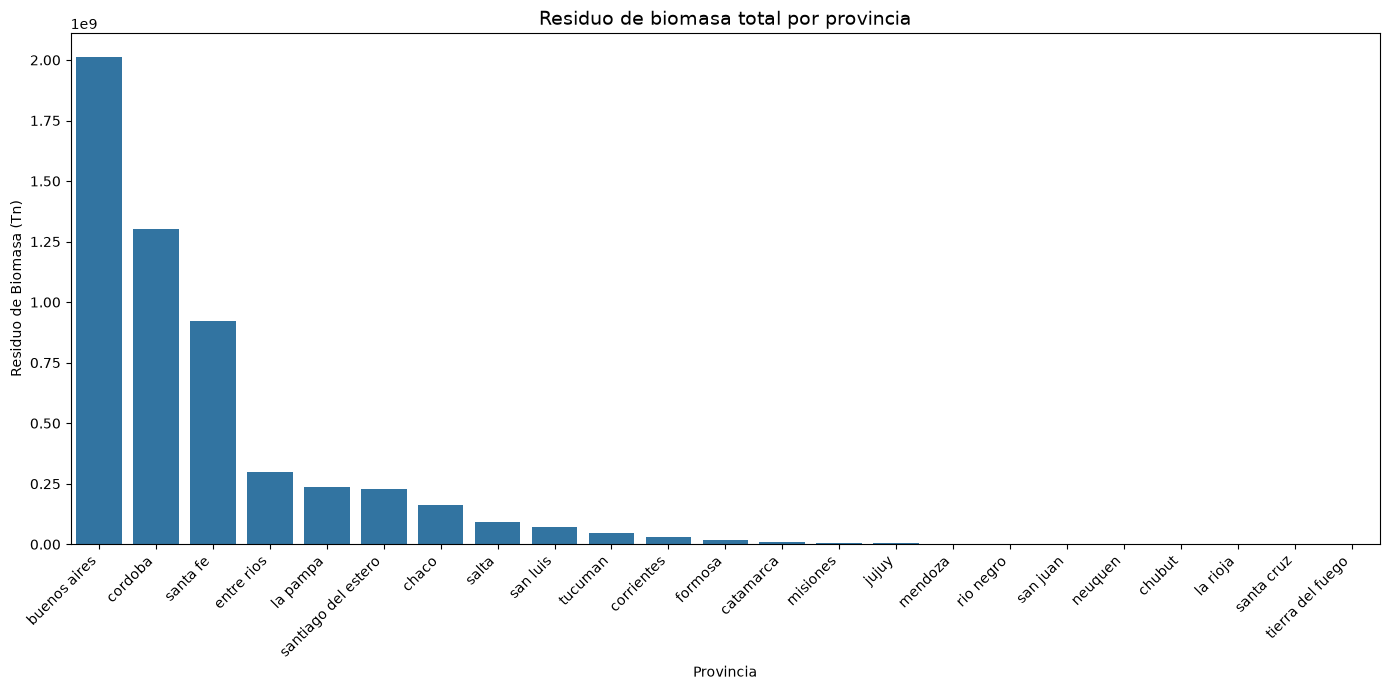

In [74]:
df_by_prov = (
    df_biomasa_validos
    .groupby("Provincia", as_index=False)[["Residuo de Biomasa (Tn)", "Produccion (Tn)"]]
    .sum()
    .sort_values("Residuo de Biomasa (Tn)", ascending=False)
)

plt.figure(figsize=(14, 7))
sns.barplot(
    data=df_by_prov,
    x="Provincia",
    y="Residuo de Biomasa (Tn)",
    order=df_by_prov["Provincia"],
)
plt.xticks(rotation=45, ha="right")
plt.title("Residuo de biomasa total por provincia", fontsize=14)
plt.ylabel("Residuo de Biomasa (Tn)")
plt.tight_layout()
plt.show()

## 15.2 Residuo de biomasa por cultivo

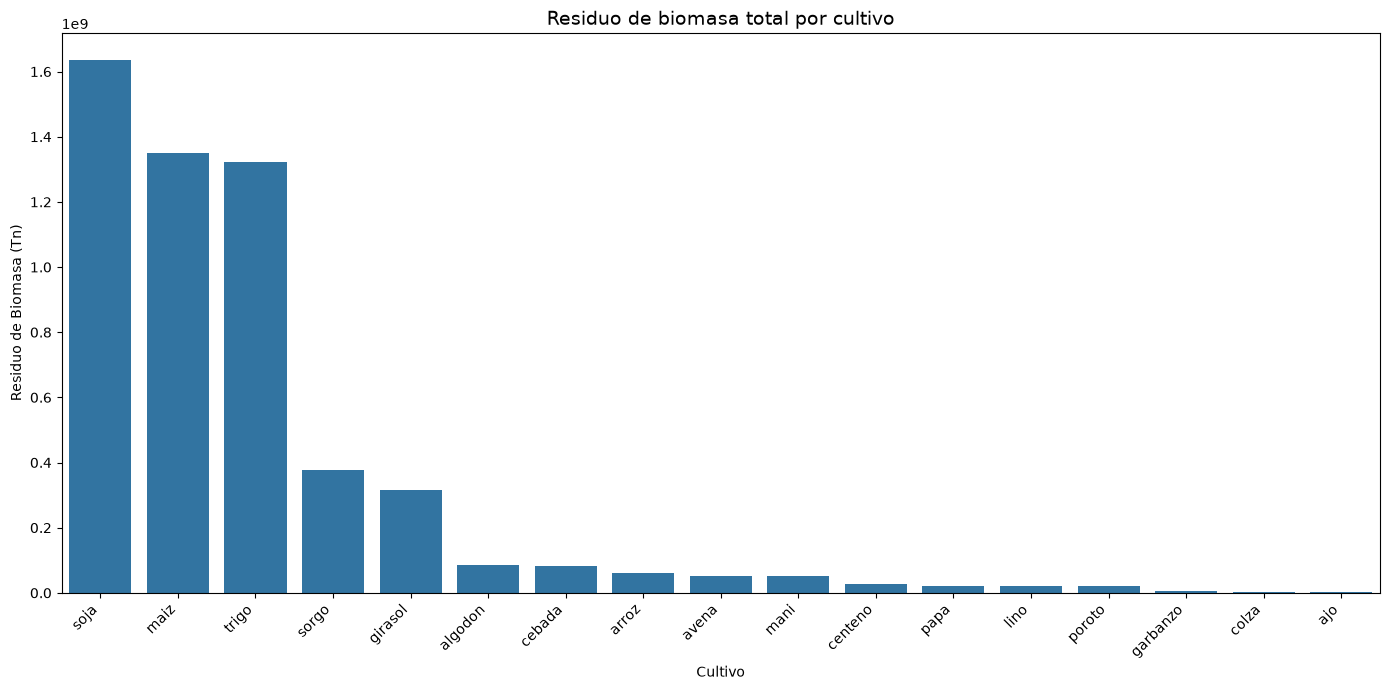

In [75]:
df_by_cultivo = (
    df_biomasa_validos
    .groupby("Cultivo", as_index=False)["Residuo de Biomasa (Tn)"]
    .sum()
    .sort_values("Residuo de Biomasa (Tn)", ascending=False)
)

plt.figure(figsize=(14, 7))
sns.barplot(
    data=df_by_cultivo,
    x="Cultivo",
    y="Residuo de Biomasa (Tn)",
    order=df_by_cultivo["Cultivo"],
)
plt.xticks(rotation=45, ha="right")
plt.title("Residuo de biomasa total por cultivo", fontsize=14)
plt.ylabel("Residuo de Biomasa (Tn)")
plt.tight_layout()
plt.show()

## 15.3 Eficiencia de generación de biomasa residual por cultivo

Se calcula el promedio **ponderado por superficie** de la densidad de biomasa residual. Un promedio simple otorgaría el mismo peso a registros de 1 Ha que a registros de 10.000 Ha, sesgando el resultado hacia departamentos con superficies marginales.

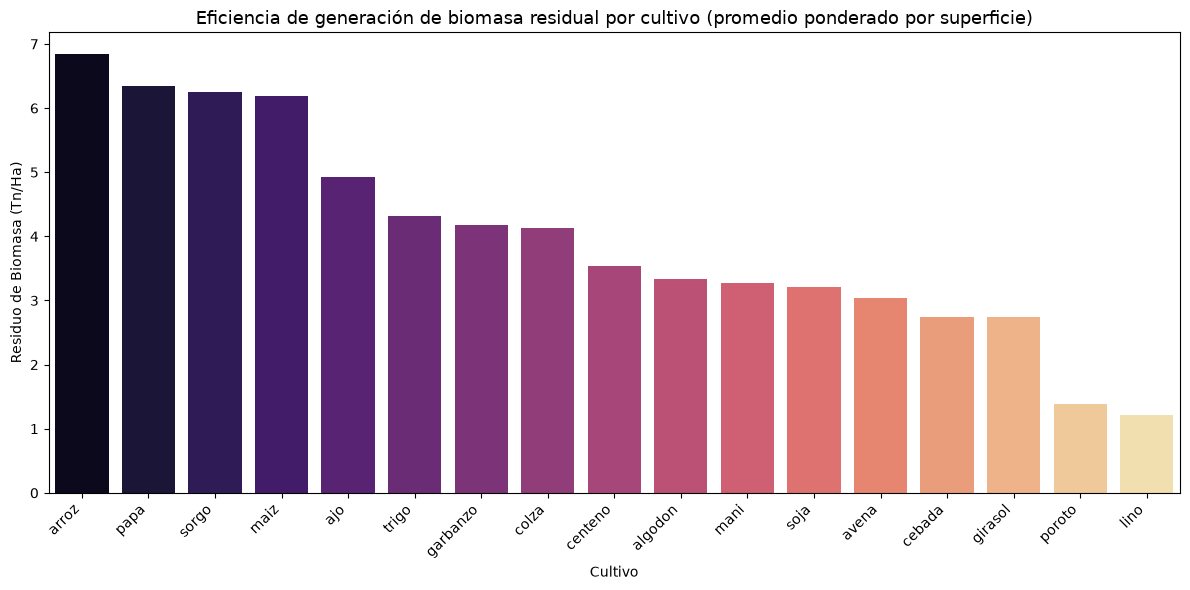

In [76]:
df_efficiency = (
    df_biomasa_validos
    .groupby("Cultivo", as_index=False)
    .apply(lambda g: pd.Series({
        "Residuo de Biomasa (Tn/Ha)": g["Residuo de Biomasa (Tn)"].sum() / g["Superficie (Ha)"].sum(),
    }))
    .reset_index(drop=True)
    .sort_values("Residuo de Biomasa (Tn/Ha)", ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_efficiency,
    x="Cultivo",
    y="Residuo de Biomasa (Tn/Ha)",
    hue="Cultivo",
    palette="magma",
    legend=False,
    order=df_efficiency["Cultivo"],
)
plt.xticks(rotation=45, ha="right")
plt.title("Eficiencia de generación de biomasa residual por cultivo (promedio ponderado por superficie)", fontsize=13)
plt.ylabel("Residuo de Biomasa (Tn/Ha)")
plt.xlabel("Cultivo")
plt.tight_layout()
plt.show()

# 16. Resumen de Limitaciones Metodológicas

1. **Cobertura geográfica asimétrica**: MAGYP cubre 23 provincias; CBA cubre 7 provincias y actúa como fallback. La prioridad MAGYP implica que para claves cubiertas por ambas, se privilegia la fuente nacional.
2. **IC asumido constante**: se asume un IC por cultivo, sin ajuste por genética, prácticas agronómicas o variabilidad regional.
3. **Cultivos sin IC excluidos**: caña de azúcar, yerba mate, cítricos y otros quedan fuera del análisis de biomasa. Esto subrepresenta geográficamente al NOA y NEA.
4. **Discrepancias entre fuentes**: se documentan y persisten como metadato, no se resuelven por promedio. En claves con cobertura múltiple, la política es prioridad institucional, no combinación estadística.
5. **Filtro de validez explícito**: el descarte de filas se realiza por flag `_valido_biomasa`, no por `dropna` global. La cobertura del análisis se reporta cuantitativamente.